# Week 1 Task 3 — Distributions and relationships

This notebook follows the Week 1 assignment brief and keeps each task in a separate file.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

path = Path('week1/assignments/data/penguins.csv')
if not path.exists():
    path = Path('assignments/data/penguins.csv')
if not path.exists():
    path = Path('d:/7_Semester/data-visualization/week1/assignments/data/penguins.csv')

df = pd.read_csv(path)
print(df.isnull().sum())
clean = df.dropna(subset=['body_mass_g', 'bill_length_mm', 'bill_depth_mm', 'sex']).copy()
print(f'Rows kept: {len(clean)} / {len(df)}')

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
Rows kept: 333 / 344


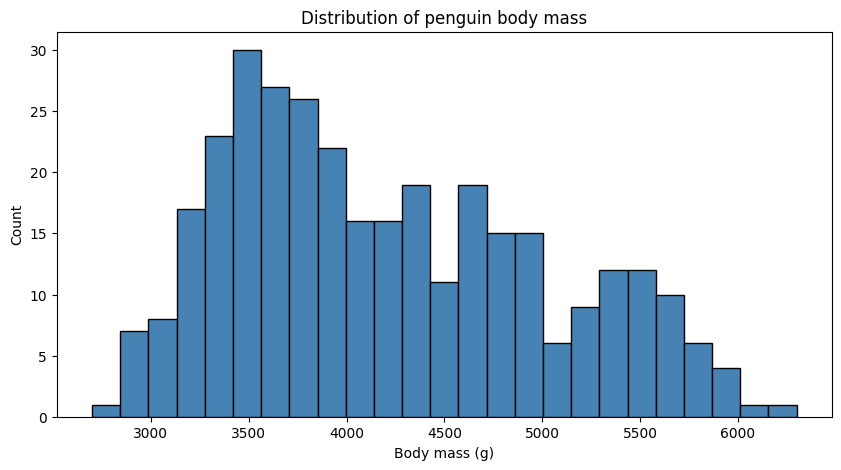

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(clean['body_mass_g'], bins=25, color='steelblue', edgecolor='black')
ax.set_title('Distribution of penguin body mass')
ax.set_xlabel('Body mass (g)')
ax.set_ylabel('Count')
plt.show()

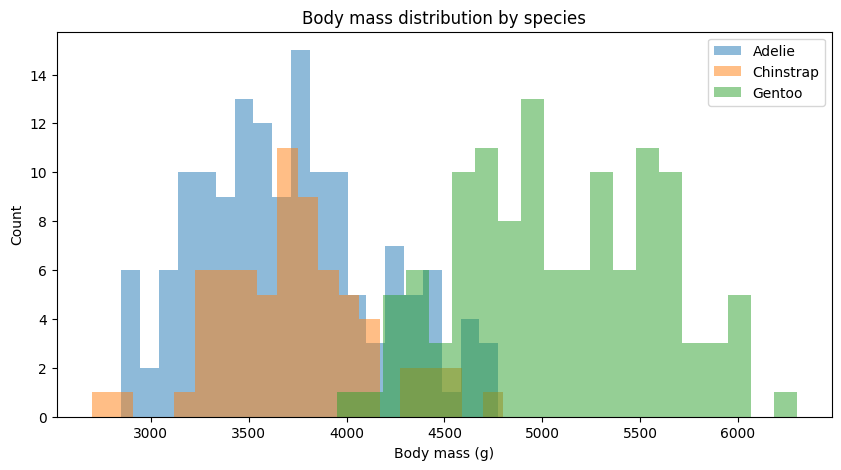

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for species, group in clean.groupby('species'):
    ax.hist(group['body_mass_g'], bins=20, alpha=0.5, label=species)
ax.set_title('Body mass distribution by species')
ax.set_xlabel('Body mass (g)')
ax.set_ylabel('Count')
ax.legend()
plt.show()

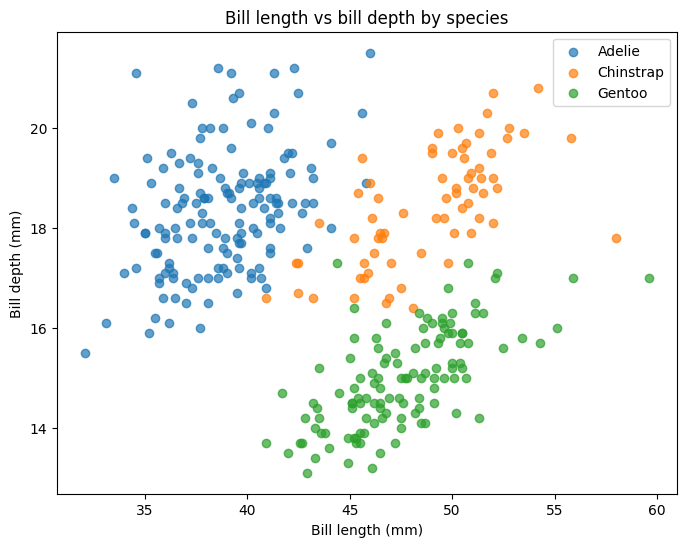

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
for species, group in clean.groupby('species'):
    ax.scatter(group['bill_length_mm'], group['bill_depth_mm'], label=species, alpha=0.7)
ax.set_title('Bill length vs bill depth by species')
ax.set_xlabel('Bill length (mm)')
ax.set_ylabel('Bill depth (mm)')
ax.legend()
plt.show()

In [ ]:
# This shows Simpson's paradox: the overall relationship is negative, but within each species it is positive. Grouping by species separates the confounding effect and makes the real pattern visible.